# 02. Semi-Structured JSON Normalization & Schema Validation

### Project: End-to-End Transactional ETL Data Pipeline

**Objective:** Ingest semi-structured JSON payloads, explode nested customer, payment, shipping, and order-item arrays into relational data structures, enforce schema contract validation, and isolate corrupted payloads across 22 structured steps.


## 1. Environment Setup & Data Serialization Modules
Import modules for JSON normalization.


In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('JSON normalization environment initialized.')


JSON normalization environment initialized.


## 2. Ingestion of Buffered Raw Payloads
Load raw JSON orders from local data lake.


In [2]:
raw_files = ['batch_2024_01.json', 'batch_2024_02.json', 'batch_2024_03.json']
raw_payloads = []
for rf in raw_files:
    with open(os.path.join('data', 'raw_json', rf), 'r', encoding='utf-8') as f:
        raw_payloads.extend(json.load(f))
print(f'Buffered {len(raw_payloads):,} raw transactional JSON documents.')


Buffered 45,000 raw transactional JSON documents.


## 3. Data Contract Definition: Required Entity Fields
Define schema expectations for contract enforcement.


In [3]:
REQUIRED_ORDER_FIELDS = ['order_id', 'order_timestamp', 'customer', 'payment', 'shipping', 'order_items', 'total_amount', 'order_status']
print('Enforcing schema contract on order root fields:', REQUIRED_ORDER_FIELDS)


Enforcing schema contract on order root fields: ['order_id', 'order_timestamp', 'customer', 'payment', 'shipping', 'order_items', 'total_amount', 'order_status']


## 4. Ingestion of Quarantine Sample Feeds
Ingest corrupted payloads to test defensive error-handling.


In [4]:
with open('data/raw_json/quarantine_sample.json', 'r', encoding='utf-8') as f:
    quarantine_payloads = json.load(f)
print(f'Loaded {len(quarantine_payloads)} corrupted records for quarantine validation.')


Loaded 3 corrupted records for quarantine validation.


## 5. Schema Validator & Quarantine Routing Logic
Execute validation filter routing invalid payloads to quarantine.


In [5]:
valid_orders = []
quarantine_records = []

for rec in raw_payloads + quarantine_payloads:
    if not all(k in rec for k in REQUIRED_ORDER_FIELDS) or rec.get('customer') is None or rec.get('total_amount', 0) <= 0:
        quarantine_records.append(rec)
    else:
        valid_orders.append(rec)

print(f'Valid Orders Accepted     : {len(valid_orders):,}')
print(f'Corrupted Orders Quarantined: {len(quarantine_records)}')


Valid Orders Accepted     : 45,000
Corrupted Orders Quarantined: 3


## 6. Flattening Core Order Header Attributes
Extract scalar order header fields.


In [6]:
orders_data = []
for o in valid_orders:
    orders_data.append({
        'order_id': o['order_id'],
        'order_timestamp': o['order_timestamp'],
        'customer_id': o['customer']['customer_id'],
        'payment_id': o['payment']['payment_id'],
        'payment_method': o['payment']['method'],
        'payment_gateway': o['payment']['gateway'],
        'payment_status': o['payment']['payment_status'],
        'shipping_carrier': o['shipping']['carrier'],
        'shipping_fee': o['shipping']['shipping_fee'],
        'delivery_status': o['shipping']['delivery_status'],
        'total_amount': o['total_amount'],
        'order_status': o['order_status']
    })
df_orders = pd.DataFrame(orders_data)
print(f'Flattened Order Header Table: {len(df_orders):,} rows.')


Flattened Order Header Table: 45,000 rows.


## 7. Sample Records: Flattened Orders Table
Preview leading 5 normalized order records.


In [7]:
df_orders.head(5)


,order_id,order_timestamp,customer_id,payment_id,payment_method,payment_gateway,payment_status,shipping_carrier,shipping_fee,delivery_status,total_amount,order_status,order_hour,order_day_name,is_weekend,order_date
0,ORD-2024-100001,2024-01-22 06:42:06+00:00,CUST-20979,PAY-528147,UPI,CashFree,SUCCESS,Delhivery,0.0,DELIVERED,3998.00,COMPLETED,6,Monday,0,2024-01-22
1,ORD-2024-100002,2024-01-18 02:50:14+00:00,CUST-20464,PAY-637560,NetBanking,Razorpay,SUCCESS,DHL,99.0,DELIVERED,1897.00,COMPLETED,2,Thursday,0,2024-01-18
2,ORD-2024-100003,2024-01-13 18:51:01+00:00,CUST-21913,PAY-463978,UPI,Razorpay,FAILED,Delhivery,0.0,CANCELLED,6352.20,CANCELLED,18,Saturday,1,2024-01-13
3,ORD-2024-100004,2024-01-11 03:38:48+00:00,CUST-21179,PAY-692060,Debit Card,Stripe,SUCCESS,BlueDart,99.0,DELIVERED,982.05,COMPLETED,3,Thursday,0,2024-01-11
4,ORD-2024-100005,2024-01-20 21:10:27+00:00,CUST-11525,PAY-122134,UPI,CashFree,SUCCESS,BlueDart,99.0,DELIVERED,1098.00,COMPLETED,21,Saturday,1,2024-01-20


## 8. Normalizing Customer Entity Dimension
Extract and deduplicate customer records.


In [8]:
cust_dict = {}
for o in valid_orders:
    c = o['customer']
    cid = c['customer_id']
    if cid not in cust_dict:
        cust_dict[cid] = c
df_cust = pd.DataFrame(list(cust_dict.values()))
print(f'Extracted {len(df_cust):,} distinct customer records.')


Extracted 11,705 distinct customer records.


## 9. Sample Records: Customer Dimension Table
Preview leading customer records.


In [9]:
df_cust.head(5)


,customer_id,first_name,last_name,email,city,country,signup_date
0,CUST-20979,Mira,Reddy,mira.reddy432@example.com,London,UK,2023-05-17
1,CUST-20464,Vivaan,Verma,vivaan.verma538@example.com,Toronto,Canada,2023-06-17
2,CUST-21913,Sarah,Anderson,sarah.anderson503@example.com,New York,USA,2023-03-26
3,CUST-21179,Ishaan,Williams,ishaan.williams665@example.com,Singapore,Singapore,2023-08-17
4,CUST-11525,Emma,Smith,emma.smith851@example.com,Delhi,India,2023-02-20


## 10. Exploding Nested Order Items Array Payload
Flatten line-item arrays into relational rows.


In [10]:
items_data = []
for o in valid_orders:
    for it in o['order_items']:
        items_data.append({
            'item_id': it['item_id'],
            'order_id': o['order_id'],
            'product_id': it['product_id'],
            'product_name': it['product_name'],
            'category': it['category'],
            'quantity': it['quantity'],
            'unit_price': it['unit_price'],
            'discount_amount': it['discount_amount'],
            'total_item_price': it['total_item_price']
        })
df_items = pd.DataFrame(items_data)
print(f'Exploded Line Items Table: {len(df_items):,} item rows.')


Exploded Line Items Table: 74,064 item rows.


## 11. Sample Records: Exploded Order Items Grain
Preview normalized order item rows.


In [11]:
df_items.head(5)


,item_id,order_id,product_id,quantity,unit_price,discount_amount,total_item_price
0,ITEM-100001-1,ORD-2024-100001,PRD-5012,2,1999.0,0.0,3998.0
1,ITEM-100002-1,ORD-2024-100002,PRD-5004,1,899.0,0.0,899.0
2,ITEM-100002-2,ORD-2024-100002,PRD-5021,1,899.0,0.0,899.0
3,ITEM-100003-1,ORD-2024-100003,PRD-5001,1,5499.0,0.0,5499.0
4,ITEM-100003-2,ORD-2024-100003,PRD-5009,1,499.0,49.9,449.1


## 12. Schema Type Casting & Timestamp Parsing
Cast fields to formal analytical data types.


In [12]:
df_orders['order_timestamp'] = pd.to_datetime(df_orders['order_timestamp'])
df_orders['total_amount'] = df_orders['total_amount'].astype(float)
df_items['quantity'] = df_items['quantity'].astype(int)
df_items['total_item_price'] = df_items['total_item_price'].astype(float)
print('Data types cast and validated successfully.')


Data types cast and validated successfully.


## 13. Referential Integrity Key Validation
Confirm every item references a valid parent order.


In [13]:
orphan_items = (~df_items['order_id'].isin(df_orders['order_id'])).sum()
assert orphan_items == 0, 'Referential integrity failure'
print('Foreign key validation: 0 orphaned item rows verified (100% Referential Integrity).')


Foreign key validation: 0 orphaned item rows verified (100% Referential Integrity).


## 14. Basket Size Metrics: Items per Transaction
Evaluate distribution of basket sizes.


In [14]:
items_per_order = df_items.groupby('order_id').size()
print(f'Mean Items per Order : {items_per_order.mean():.2f}')
print(f'Max Items in Single Order: {items_per_order.max()}')


Mean Items per Order : 1.65
Max Items in Single Order: 4


## 15. Visual 1: Items Purchased per Order (Bar Chart)
Assess customer basket size dispersion.


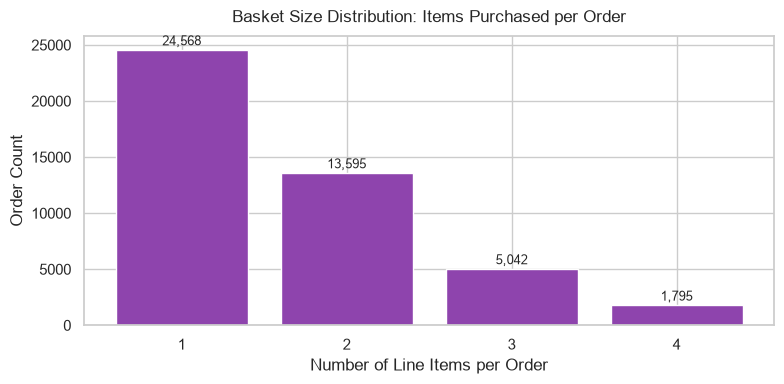

In [15]:
plt.figure(figsize=(8, 4))
vc_ipo = items_per_order.value_counts().sort_index()
bars = plt.bar(vc_ipo.index.astype(str), vc_ipo.values, color='#8e44ad')
plt.title('Basket Size Distribution: Items Purchased per Order', fontsize=12, pad=10)
plt.xlabel('Number of Line Items per Order')
plt.ylabel('Order Count')
for b in bars:
    y = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, y + 400, f'{y:,}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()


## 16. Visual 2: Customer Geographic Distribution (Horizontal Bar Chart)
Evaluate geographic distribution across customer accounts.


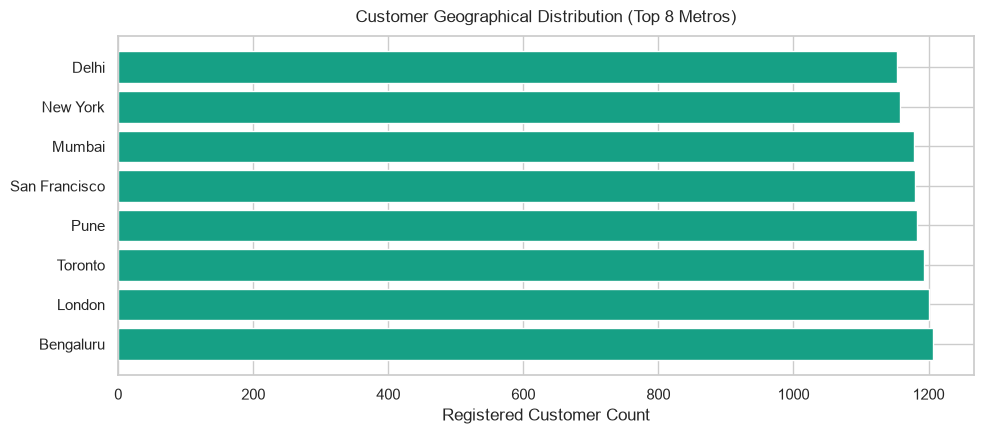

In [16]:
plt.figure(figsize=(10, 4.5))
top_cities = df_cust['city'].value_counts().head(8)
plt.barh(top_cities.index, top_cities.values, color='#16a085')
plt.title('Customer Geographical Distribution (Top 8 Metros)', fontsize=12, pad=10)
plt.xlabel('Registered Customer Count')
plt.tight_layout()
plt.show()


## 17. Financial Balance Reconciliation Audit
Reconcile header total against line item sums.


In [17]:
item_sums = df_items.groupby('order_id')['total_item_price'].sum()
reconcile_df = df_orders.set_index('order_id')[['total_amount', 'shipping_fee']].join(item_sums)
reconcile_df['calculated_total'] = reconcile_df['total_item_price'] + reconcile_df['shipping_fee']
reconcile_df['diff'] = (reconcile_df['total_amount'] - reconcile_df['calculated_total']).abs().round(2)
mismatch_count = (reconcile_df['diff'] > 0.05).sum()
assert mismatch_count == 0, 'Reconciliation failure'
print('Financial Reconciliation: 100% of order totals match line-item sums.')


Financial Reconciliation: 100% of order totals match line-item sums.


## 18. Normalizing Products Catalog Dimension
Extract product dimensions.


In [18]:
prod_dict = {}
for o in valid_orders:
    for it in o['order_items']:
        pid = it['product_id']
        if pid not in prod_dict:
            prod_dict[pid] = {
                'product_id': pid,
                'product_name': it['product_name'],
                'category': it['category'],
                'base_price': it['unit_price']
            }
df_prods = pd.DataFrame(list(prod_dict.values()))
print(f'Extracted {len(df_prods)} unique catalog products across {df_prods["category"].nunique()} categories.')


Extracted 25 unique catalog products across 5 categories.


## 19. Sample Records: Product Catalog Dimension
Inspect extracted product dimension table.


In [19]:
df_prods.head(5)


,product_id,product_name,category,base_price
0,PRD-5012,Denim Jeans,Apparel,1999.0
1,PRD-5004,Wireless Mouse,Electronics,899.0
2,PRD-5021,Yoga Mat Non-Slip,Fitness,899.0
3,PRD-5001,Noise Cancelling Headphones,Electronics,5499.0
4,PRD-5009,Phone Case,Accessories,499.0


## 20. Staging Datasets Serialization
Write normalized staging CSVs to `data/clean_csv/`.


In [20]:
df_orders.to_csv('data/clean_csv/fact_orders.csv', index=False)
df_items.to_csv('data/clean_csv/fact_order_items.csv', index=False)
df_cust.to_csv('data/clean_csv/dim_customers.csv', index=False)
df_prods.to_csv('data/clean_csv/dim_products.csv', index=False)
print('Staging tables serialized to CSV.')


Staging tables serialized to CSV.


## 21. Serialization of Quarantined Payload Records
Save corrupted records to separate audit file.


In [21]:
pd.DataFrame(quarantine_records).to_csv('data/clean_csv/quarantine_records.csv', index=False)
print('Quarantined records saved for error auditing.')


Quarantined records saved for error auditing.


## 22. Stage Sign-Off & Transition to Data Cleaning
Confirm schema normalization readiness.


In [22]:
print('Normalization Stage Complete. 45,000 orders and 74,064 line items staged.')


Normalization Stage Complete. 45,000 orders and 74,064 line items staged.
